# Synthetic Alert Generation — Benign + Malicious
## ReALTabFormer Pipeline

**Goal**: Generate a balanced synthetic dataset:
- **90,000 synthetic benign alerts** (from new benign-trained RTF models)
- **30,000 synthetic malicious alerts** (from existing CKC-trained RTF models)
- **120,000 total** → reverse-mapped to original dataset columns

**Data Sources**:
- `combined_dataset_final.xlsx` → ~90K benign rows for training benign models
- `malicious_realtabformer_filtered.xlsx` → existing malicious RTF models
- SecBERT embeddings for text decoding


In [4]:
# ============================================================================
# WARNING SUPPRESSION & ENVIRONMENT SETUP
# ============================================================================
import os, sys, warnings

os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'
os.environ['CUDA_VISIBLE_DEVICES'] = os.environ.get('CUDA_VISIBLE_DEVICES', '0')
os.environ['GRPC_VERBOSITY'] = 'ERROR'
os.environ['GLOG_minloglevel'] = '3'
os.environ['ABSL_MIN_LOG_LEVEL'] = '3'
os.environ['TOKENIZERS_PARALLELISM'] = 'false'
os.environ['WANDB_DISABLED'] = 'true'
os.environ['WANDB_MODE'] = 'disabled'
os.environ['JAX_PLATFORMS'] = ''

warnings.filterwarnings('ignore')
if not sys.warnoptions:
    warnings.simplefilter("ignore")

import logging
logging.getLogger().setLevel(logging.ERROR)
for name in ['absl', 'tensorflow', 'transformers', 'realtabformer']:
    logging.getLogger(name).setLevel(logging.ERROR)

try:
    import tensorflow as tf
    tf.get_logger().setLevel('ERROR')
    tf.autograph.set_verbosity(0)
except ImportError:
    pass

print("All warning suppressions activated")

All warning suppressions activated


In [2]:
# ============================================================================
# CORE IMPORTS
# ============================================================================
import json, re, math, types, pickle, secrets
from pathlib import Path
from glob import glob
from datetime import datetime
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, f1_score
from sklearn.manifold import TSNE
from tqdm.auto import tqdm

from realtabformer import REaLTabFormer
from transformers import GPT2Config, GPT2LMHeadModel

SECBERT_AVAILABLE = False
try:
    from sentence_transformers import SentenceTransformer
    SECBERT_AVAILABLE = True
except ImportError:
    pass

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Device: {device}")
if device == 'cuda':
    print(f"   GPU: {torch.cuda.get_device_name(0)}")
    print(f"   VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")
print(f"SecBERT available: {SECBERT_AVAILABLE}")

c:\Users\KassoussiOussama-PFE\Downloads\pfe\.venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm



Device: cuda
   GPU: NVIDIA GeForce RTX 2060 SUPER
   VRAM: 8.6 GB
SecBERT available: True


In [5]:
# ============================================================================
# CONFIGURATION
# ============================================================================

PARENT_DIR = r'c:\Users\KassoussiOussama-PFE\Downloads\pfe'
OUTPUT_DIR = r'D:\PFE_BENIGN_MAL'
os.makedirs(OUTPUT_DIR, exist_ok=True)

CONFIG = {
    # Data paths
    'combined_data_path': os.path.join(PARENT_DIR, 'combined_dataset_final.xlsx'),
    'malicious_data_path': os.path.join(PARENT_DIR, 'malicious_realtabformer_filtered.xlsx'),
    'embeddings_path': os.path.join(PARENT_DIR, 'realtabformer_output', 'secbert_embeddings.pkl'),
    # Existing malicious models (from CKC notebook)
    'malicious_model_dir': os.path.join(r'D:\PFE_CKC', 'ckc_models'),
    # Benign model dirs
    'benign_checkpoints_dir': os.path.join(OUTPUT_DIR, 'benign_checkpoints'),
    'benign_model_dir': os.path.join(OUTPUT_DIR, 'benign_models'),
    # Training
    'epochs': 150, 'batch_size': 32, 'gradient_accumulation_steps': 4,
    'logging_steps': 100, 'save_steps': 500, 'train_size': 0.95,
    'random_seed': 42,
    # Generation targets
    'n_benign_target': 90_000,
    'n_malicious_target': 30_000,
    'oversample_factor': 1.3,   # generate 30% more than target, then sample down
    # SecBERT
    'secbert_model': 'jackaduma/SecBERT',
    'n_pca_dims': 16,
    'device': device,
}

# Top 25 distinct features (same as CKC notebook)
TOP_25_FEATURES = [
    'log_secbert_embedding',
    'decoder_auditd',
    'firedtimes',
    'location__var_log_audit_audit.log',
    'srcip_is_private',
    'decoder_web-accesslog',
    'location__var_log_apache2_access.log',
    'firedtimes_log',
    'path_is_missing',
    'has_md5',
    'cmd_length',
    'has_sha256',
    'syscheck_added',
    'cmd_is_missing',
    'decoder_dpkg-decoder',
    'syscheck_deleted',
    'path_depth',
    'syscheck_modified',
    'location__var_log_auth.log',
    'cmd_secbert_embedding',
    'decoder_syscheck_deleted',
    'path_is_sensitive',
    'decoder_syscheck_integrity_changed',
    'location_syscheck',
    'path_is_temp',
]

N_PCA = CONFIG['n_pca_dims']

def expand_feature_list(features):
    expanded = []
    for f in features:
        if f == 'log_secbert_embedding':
            expanded.extend([f'log_secbert_emb_{i}' for i in range(N_PCA)])
        elif f == 'cmd_secbert_embedding':
            expanded.extend([f'cmd_secbert_emb_{i}' for i in range(N_PCA)])
        else:
            expanded.append(f)
    return expanded

TOP_25_COLUMNS = expand_feature_list(TOP_25_FEATURES)

print(f"CONFIG:")
print(f"   Top 25 features -> {len(TOP_25_COLUMNS)} DataFrame columns")
print(f"   Benign target:    {CONFIG['n_benign_target']:,}")
print(f"   Malicious target: {CONFIG['n_malicious_target']:,}")
print(f"   Total target:     {CONFIG['n_benign_target'] + CONFIG['n_malicious_target']:,}")
print(f"   Output: {OUTPUT_DIR}")

CONFIG:
   Top 25 features -> 55 DataFrame columns
   Benign target:    90,000
   Malicious target: 30,000
   Total target:     120,000
   Output: D:\PFE_BENIGN_MAL


In [16]:
# ============================================================================
# LOAD COMBINED DATASET & ENGINEER TOP 25 FEATURES (BOTH CLASSES)
# ============================================================================

print("=" * 70)
print("LOADING COMBINED DATASET & ENGINEERING FEATURES")
print("=" * 70)

# 1. Load combined dataset
combined_df = pd.read_excel(CONFIG['combined_data_path'], sheet_name='Sheet1')
print(f"   Combined data: {combined_df.shape[0]:,} rows x {combined_df.shape[1]} cols")

for col in combined_df.select_dtypes(include='object').columns:
    mask = combined_df[col].isin([' ', '  ', ''])
    combined_df.loc[mask, col] = np.nan

# Split benign / malicious
benign_raw = combined_df[combined_df['malicious'] == 0].copy().reset_index(drop=True)
malicious_raw = combined_df[combined_df['malicious'] == 1].copy().reset_index(drop=True)
print(f"   Benign:    {len(benign_raw):,} rows")
print(f"   Malicious: {len(malicious_raw):,} rows")

# 2. Load existing SecBERT embeddings (malicious-only, 25,418 rows)
print(f"\nLoading existing SecBERT embeddings (malicious only)...")
with open(CONFIG['embeddings_path'], 'rb') as f:
    text_embeddings = pickle.load(f)

mal_log_emb = text_embeddings.get('_source.rule.description')  # (25418, 768)
mal_cmd_emb = text_embeddings.get('_source.data.command')       # (25418, 768)
print(f"   Malicious rule.description: {mal_log_emb.shape}")
print(f"   Malicious data.command:     {mal_cmd_emb.shape}")

# 3. Compute SecBERT embeddings for BENIGN rows
print(f"\nComputing SecBERT embeddings for {len(benign_raw):,} benign rows...")
from sentence_transformers import SentenceTransformer
secbert = SentenceTransformer(CONFIG['secbert_model'])
if device == 'cuda':
    secbert = secbert.to(torch.device(device))

def encode_column(df, col_name, model, batch_size=512):
    texts = df[col_name].fillna('').astype(str).tolist()
    texts = [t if t not in ['nan', 'None', 'NaN', ''] else 'empty' for t in texts]
    embeddings = model.encode(texts, batch_size=batch_size, show_progress_bar=True,
                               convert_to_numpy=True)
    return embeddings

ben_log_emb = encode_column(benign_raw, '_source.rule.description', secbert)
print(f"   Benign rule.description: {ben_log_emb.shape}")
ben_cmd_emb = encode_column(benign_raw, '_source.data.command', secbert)
print(f"   Benign data.command:     {ben_cmd_emb.shape}")

# Save benign embeddings for future use
benign_emb_path = os.path.join(OUTPUT_DIR, 'benign_secbert_embeddings.pkl')
with open(benign_emb_path, 'wb') as f:
    pickle.dump({'_source.rule.description': ben_log_emb, '_source.data.command': ben_cmd_emb}, f)
print(f"   Benign embeddings saved to: {benign_emb_path}")

# Free SecBERT from GPU
del secbert
if device == 'cuda':
    torch.cuda.empty_cache()

# 4. PCA — fit on ALL data combined, transform separately
RANDOM_SEED = CONFIG['random_seed']

all_log_emb = np.vstack([ben_log_emb, mal_log_emb])
all_cmd_emb = np.vstack([ben_cmd_emb, mal_cmd_emb])

pca_log = PCA(n_components=N_PCA, random_state=RANDOM_SEED)
all_log_pca = pca_log.fit_transform(all_log_emb)
print(f"\n   Log PCA: {all_log_emb.shape[1]}D -> {N_PCA}D (var: {pca_log.explained_variance_ratio_.sum():.3f})")

pca_cmd = PCA(n_components=N_PCA, random_state=RANDOM_SEED)
all_cmd_pca = pca_cmd.fit_transform(all_cmd_emb)
print(f"   Cmd PCA: {all_cmd_emb.shape[1]}D -> {N_PCA}D (var: {pca_cmd.explained_variance_ratio_.sum():.3f})")

# Split PCA results: benign first, malicious second in the stacked array
n_ben = len(benign_raw)
ben_log_pca = all_log_pca[:n_ben]
mal_log_pca = all_log_pca[n_ben:]
ben_cmd_pca = all_cmd_pca[:n_ben]
mal_cmd_pca = all_cmd_pca[n_ben:]

# Free 768-dim arrays
del all_log_emb, all_cmd_emb, all_log_pca, all_cmd_pca

# 5. Engineer features for EACH class
def engineer_features(raw_df, log_pca, cmd_pca, label):
    df = pd.DataFrame(index=raw_df.index)
    for feat in TOP_25_FEATURES:
        if feat == 'log_secbert_embedding':
            for i in range(N_PCA):
                df[f'log_secbert_emb_{i}'] = log_pca[:, i]
        elif feat == 'cmd_secbert_embedding':
            for i in range(N_PCA):
                df[f'cmd_secbert_emb_{i}'] = cmd_pca[:, i]
        elif feat == 'firedtimes':
            df[feat] = raw_df['_source.rule.firedtimes'].fillna(0).astype(float)
        elif feat == 'firedtimes_log':
            df[feat] = np.log1p(raw_df['_source.rule.firedtimes'].fillna(0).astype(float))
        elif feat == 'cmd_length':
            df[feat] = raw_df['_source.data.command'].fillna('').astype(str).str.len()
        elif feat == 'path_depth':
            df[feat] = raw_df['_source.syscheck.path'].fillna('').astype(str).str.count('/').astype(int)
        elif feat.startswith('decoder_'):
            decoder_name = feat.replace('decoder_', '')
            df[feat] = (raw_df['_source.decoder.name'].astype(str) == decoder_name).astype(int)
        elif feat.startswith('location_'):
            loc_name = feat.replace('location_', '').replace('_', '/')
            df[feat] = raw_df['_source.location'].astype(str).str.contains(loc_name, na=False).astype(int)
        elif feat == 'srcip_is_private':
            def _is_private(ip):
                if pd.isna(ip): return 0
                s = str(ip)
                return int(s.startswith('10.') or s.startswith('192.168.') or
                          (s.startswith('172.') and len(s.split('.'))>1 and 16<=int(s.split('.')[1])<=31))
            df[feat] = raw_df['_source.data.srcip'].apply(_is_private)
        elif feat == 'has_md5':
            df[feat] = raw_df['_source.syscheck.md5_after'].notna().astype(int)
        elif feat == 'has_sha256':
            df[feat] = raw_df['_source.syscheck.sha256_after'].notna().astype(int)
        elif feat == 'syscheck_added':
            df[feat] = (raw_df['_source.syscheck.event'].astype(str).str.lower() == 'added').astype(int)
        elif feat == 'syscheck_deleted':
            df[feat] = (raw_df['_source.syscheck.event'].astype(str).str.lower() == 'deleted').astype(int)
        elif feat == 'syscheck_modified':
            df[feat] = (raw_df['_source.syscheck.event'].astype(str).str.lower() == 'modified').astype(int)
        elif feat == 'path_is_missing':
            df[feat] = raw_df['_source.syscheck.path'].isna().astype(int)
        elif feat == 'path_is_sensitive':
            sensitive_dirs = ['/etc', '/root', '/var/log', '/boot', '/usr/sbin']
            df[feat] = raw_df['_source.syscheck.path'].fillna('').astype(str).apply(
                lambda p: int(any(d in p for d in sensitive_dirs)))
        elif feat == 'path_is_temp':
            df[feat] = raw_df['_source.syscheck.path'].fillna('').astype(str).apply(
                lambda p: int('/tmp' in p or '/temp' in p))
        elif feat == 'cmd_is_missing':
            df[feat] = raw_df['_source.data.command'].isna().astype(int)

    # Add command column for training (text)
    df['_source.data.command'] = raw_df['_source.data.command'].fillna('').astype(str).str[:300]
    df['_source.data.command'] = df['_source.data.command'].replace({'nan': '', 'None': '', 'NaN': ''})

    # Source type
    SOURCE_TYPES = {
        'network':  ['_source.data.protocol', '_source.data.srcip', '_source.data.url'],
        'syscheck': ['_source.syscheck.event', '_source.syscheck.path'],
        'sca':      ['_source.data.sca.check.result'],
        'audit':    ['_source.data.audit.syscall', '_source.data.audit.exe'],
    }
    raw_df2 = raw_df.copy()
    raw_df2['_source_type'] = 'base'
    for stype, detect_cols in SOURCE_TYPES.items():
        existing = [c for c in detect_cols if c in raw_df2.columns]
        if existing:
            msk = raw_df2[existing].notna().any(axis=1)
            raw_df2.loc[msk, '_source_type'] = stype
    df['_source_type'] = raw_df2['_source_type'].values

    print(f"   [{label}] Engineered: {df.shape[0]:,} rows x {df.shape[1]} cols")
    return df

benign_eng = engineer_features(benign_raw, ben_log_pca, ben_cmd_pca, 'BENIGN')
malicious_eng = engineer_features(malicious_raw, mal_log_pca, mal_cmd_pca, 'MALICIOUS')

# Save PCA models
pca_models = {'log': pca_log, 'cmd': pca_cmd}
with open(os.path.join(OUTPUT_DIR, 'pca_models.pkl'), 'wb') as f:
    pickle.dump(pca_models, f)
print(f"\nPCA models saved")

# Source type distribution
for label, df_eng in [('BENIGN', benign_eng), ('MALICIOUS', malicious_eng)]:
    print(f"\n   {label} source types:")
    for st, cnt in df_eng['_source_type'].value_counts().items():
        print(f"      {st}: {cnt:,}")

LOADING COMBINED DATASET & ENGINEERING FEATURES
   Combined data: 115,726 rows x 176 cols
   Benign:    90,308 rows
   Malicious: 25,418 rows

Loading existing SecBERT embeddings (malicious only)...
   Malicious rule.description: (25418, 768)
   Malicious data.command:     (25418, 768)

Computing SecBERT embeddings for 90,308 benign rows...


Batches: 100%|██████████| 177/177 [19:21<00:00,  6.56s/it]


   Benign rule.description: (90308, 768)


Batches: 100%|██████████| 177/177 [05:05<00:00,  1.73s/it]


   Benign data.command:     (90308, 768)
   Benign embeddings saved to: D:\PFE_BENIGN_MAL\benign_secbert_embeddings.pkl

   Log PCA: 768D -> 16D (var: 0.898)
   Cmd PCA: 768D -> 16D (var: 0.998)
   [BENIGN] Engineered: 90,308 rows x 57 cols
   [MALICIOUS] Engineered: 25,418 rows x 57 cols

PCA models saved

   BENIGN source types:
      audit: 76,728
      network: 8,618
      base: 3,611
      syscheck: 1,275
      sca: 76

   MALICIOUS source types:
      network: 18,920
      syscheck: 2,862
      base: 2,601
      sca: 870
      audit: 165


In [17]:
# ============================================================================
# STRATIFIED PREPROCESSING — BENIGN DATA FOR TRAINING
# ============================================================================

print("=" * 70)
print("BUILDING STRATIFIED TRAINING DATASETS — BENIGN")
print("=" * 70)

LOG_EMB_COLS = [f'log_secbert_emb_{i}' for i in range(N_PCA)]
CMD_EMB_COLS = [f'cmd_secbert_emb_{i}' for i in range(N_PCA)]

# For benign: no CKC/MITRE columns needed
UNIVERSAL_FEATURES_BENIGN = (
    LOG_EMB_COLS + CMD_EMB_COLS +
    ['firedtimes', 'firedtimes_log', 'cmd_length', 'cmd_is_missing',
     '_source.data.command']
)

SOURCE_SPECIFIC = {
    'network':  ['srcip_is_private', 'decoder_web-accesslog', 'location__var_log_apache2_access.log'],
    'syscheck': ['syscheck_added', 'syscheck_deleted', 'syscheck_modified',
                 'path_is_missing', 'path_depth', 'path_is_sensitive', 'path_is_temp',
                 'has_md5', 'has_sha256',
                 'decoder_syscheck_deleted', 'decoder_syscheck_integrity_changed', 'location_syscheck'],
    'audit':    ['decoder_auditd', 'location__var_log_audit_audit.log'],
    'sca':      [],
    'base':     ['decoder_dpkg-decoder', 'location__var_log_auth.log'],
}

def preprocess_stratum(df_sub, columns, name):
    existing = [c for c in columns if c in df_sub.columns]
    df = df_sub[existing].copy()
    col_types = {'text': [], 'categorical': [], 'numeric': []}

    for col in df.columns:
        dtype = df[col].dtype
        n_unique = df[col].nunique()
        if dtype == 'object':
            if n_unique > 100:
                col_types['text'].append(col)
                max_len = 300 if 'command' in col else 150
                df[col] = df[col].fillna('').astype(str).str[:max_len]
                df[col] = df[col].replace({'nan': '', 'None': '', 'NaN': ''})
            else:
                col_types['categorical'].append(col)
                df[col] = df[col].fillna('MISSING').astype(str)
        elif dtype in ['int64', 'float64', 'int32', 'float32']:
            if n_unique <= 20:
                col_types['categorical'].append(col)
                df[col] = df[col].fillna(-1).astype(int).astype(str)
            else:
                col_types['numeric'].append(col)
        else:
            col_types['categorical'].append(col)
            df[col] = df[col].fillna('MISSING').astype(str)

    print(f"   {name.upper()}: {df.shape[0]:,} rows x {df.shape[1]} cols "
          f"(text:{len(col_types['text'])} cat:{len(col_types['categorical'])} num:{len(col_types['numeric'])})")
    return df, col_types

benign_strata = {}
for stype in ['network', 'syscheck', 'sca', 'audit', 'base']:
    subset = benign_eng[benign_eng['_source_type'] == stype].copy()
    if len(subset) == 0:
        print(f"   {stype}: 0 rows -- skipping")
        continue
    cols = UNIVERSAL_FEATURES_BENIGN + SOURCE_SPECIFIC.get(stype, [])
    cols = [c for c in cols if c in benign_eng.columns]
    df_proc, col_types = preprocess_stratum(subset, cols, f'benign_{stype}')
    benign_strata[stype] = {
        'df': df_proc, 'col_types': col_types,
        'all_cols': list(df_proc.columns), 'n_rows': len(df_proc),
    }

print(f"\nBENIGN STRATA SUMMARY:")
total_rows = sum(s['n_rows'] for s in benign_strata.values())
for stype, info in benign_strata.items():
    pct = info['n_rows'] / total_rows * 100
    print(f"   {stype:>10}: {info['n_rows']:>6,} rows x {len(info['all_cols']):>2} cols ({pct:.1f}%)")
print(f"   {'TOTAL':>10}: {total_rows:>6,} rows")
print("=" * 70)

BUILDING STRATIFIED TRAINING DATASETS — BENIGN
   BENIGN_NETWORK: 8,618 rows x 40 cols (text:0 cat:38 num:2)
   BENIGN_SYSCHECK: 1,275 rows x 49 cols (text:0 cat:47 num:2)
   BENIGN_SCA: 76 rows x 37 cols (text:0 cat:35 num:2)
   BENIGN_AUDIT: 76,728 rows x 39 cols (text:0 cat:21 num:18)
   BENIGN_BASE: 3,611 rows x 39 cols (text:0 cat:21 num:18)

BENIGN STRATA SUMMARY:
      network:  8,618 rows x 40 cols (9.5%)
     syscheck:  1,275 rows x 49 cols (1.4%)
          sca:     76 rows x 37 cols (0.1%)
        audit: 76,728 rows x 39 cols (85.0%)
         base:  3,611 rows x 39 cols (4.0%)
        TOTAL: 90,308 rows


In [18]:
# ============================================================================
# GPU-OPTIMIZED SENSITIVITY THRESHOLD + TRAINING UTILITIES
# ============================================================================

def gpu_manhattan_distances(X, Y, device='cuda', batch_size=2000):
    X_t = torch.tensor(X, dtype=torch.float32, device=device)
    Y_t = torch.tensor(Y, dtype=torch.float32, device=device)
    if X_t.shape[0] * Y_t.shape[0] > 100_000_000:
        distances = np.zeros((X_t.shape[0], Y_t.shape[0]), dtype=np.float32)
        for i in range(0, X_t.shape[0], batch_size):
            batch = X_t[i:min(i + batch_size, X_t.shape[0])]
            distances[i:i+len(batch)] = torch.cdist(batch, Y_t, p=1).cpu().numpy()
        return distances
    return torch.cdist(X_t, Y_t, p=1).cpu().numpy()

def fast_preprocess_for_threshold(data, embedding_pca_dims=50, verbose=False):
    features = []
    numeric_cols = data.select_dtypes(include=['number']).columns.tolist()
    if numeric_cols:
        numeric_data = data[numeric_cols].fillna(0).values
        features.append(StandardScaler().fit_transform(numeric_data))
    cat_cols = data.select_dtypes(include=['object', 'category']).columns.tolist()
    low_card = [c for c in cat_cols if data[c].nunique() <= 100]
    if low_card:
        cat_feats = np.hstack([data[c].astype('category').cat.codes.values.reshape(-1,1) for c in low_card]).astype(np.float32)
        features.append(StandardScaler().fit_transform(cat_feats))
    if features:
        combined = np.hstack(features).astype(np.float32)
    else:
        combined = np.zeros((len(data), 1), dtype=np.float32)
    return np.nan_to_num(combined, nan=0.0)

def compute_sensitivity_threshold_fast(train_data, num_bootstrap=200, frac=0.165,
                                        qt_max=0.05, qt_interval=500, quantile=0.95,
                                        max_col_nums=50, device='cuda'):
    preprocessed = fast_preprocess_for_threshold(train_data)
    n_samples = len(preprocessed)
    indices = np.arange(n_samples)
    np.random.seed(42)
    values = []
    for _ in tqdm(range(num_bootstrap), desc="   Bootstrap", leave=False):
        train_idx, test_idx = train_test_split(indices, test_size=2*frac)
        split = len(test_idx) // 2
        syn_idx, tst_idx = test_idx[:split], test_idx[split:]
        orig, syn, tst = preprocessed[train_idx], preprocessed[syn_idx], preprocessed[tst_idx]
        if orig.shape[1] >= max_col_nums:
            tsvd = TruncatedSVD(n_components=max(5, math.ceil(orig.shape[1]**0.5)))
            orig = tsvd.fit_transform(orig)
            tst = tsvd.transform(tst)
            syn = tsvd.transform(syn)
        td = gpu_manhattan_distances(orig, tst, device=device)
        sd = gpu_manhattan_distances(orig, syn, device=device)
        t_min, s_min = td.min(axis=1), sd.min(axis=1)
        tr_t, tr_s = td.min(axis=0), sd.min(axis=0)
        fltr = (s_min == 0) & (t_min == 0)
        t_min, s_min = t_min[~fltr], s_min[~fltr]
        t_min = np.concatenate([t_min, tr_t])
        s_min = np.concatenate([s_min, tr_s])
        quantiles = np.linspace(0, qt_max, qt_interval)
        stat = np.mean((s_min.reshape(1,-1) <= np.quantile(t_min, quantiles).reshape(-1,1)).mean(axis=1) - quantiles)
        values.append(stat)
    threshold = np.quantile(values, quantile)
    return {'threshold': threshold, 'mean': np.mean(values), 'values': values}

def patched_save(self, path, allow_overwrite=False):
    path = Path(path)
    path.mkdir(parents=True, exist_ok=True)
    rtf_attrs = {}
    for key, value in self.__dict__.items():
        if key.startswith('_') and key != '_column_order': continue
        if key in ['model', 'trainer', 'tokenizer', 'data_collator']: continue
        try:
            json.dumps(value, default=str)
            if isinstance(value, Path): rtf_attrs[key] = value.as_posix()
            elif hasattr(value, '__class__') and value.__class__.__name__ == 'Dataset': continue
            else: rtf_attrs[key] = value
        except (TypeError, ValueError): continue
    for attr in ["checkpoints_dir", "samples_save_dir", "full_save_dir"]:
        if attr in rtf_attrs and hasattr(rtf_attrs[attr], 'as_posix'):
            rtf_attrs[attr] = rtf_attrs[attr].as_posix()
    def json_enc(obj):
        if isinstance(obj, Path): return obj.as_posix()
        if hasattr(obj, 'tolist'): return obj.tolist()
        return str(obj)
    (path / "rtf_config.json").write_text(json.dumps(rtf_attrs, default=json_enc, indent=2))
    if hasattr(self, 'model') and self.model is not None: self.model.save_pretrained(path)
    if hasattr(self, 'tokenizer') and self.tokenizer is not None: self.tokenizer.save_pretrained(path)

print("GPU optimization & training utilities loaded")

GPU optimization & training utilities loaded


## Phase 1: Train Benign RTF Models
Train 5 ReALTabFormer models (one per source type) on the ~90K benign rows.
Skip this cell if models are already trained — use the loader cell below.


In [9]:
# ============================================================================
# TRAIN REaLTabFormer — BENIGN MODELS (ONE PER SOURCE TYPE)
# ============================================================================

print("=" * 70)
print("TRAINING BENIGN REaLTabFormer MODELS")
print("=" * 70)

os.makedirs(CONFIG['benign_checkpoints_dir'], exist_ok=True)
os.makedirs(CONFIG['benign_model_dir'], exist_ok=True)

benign_trained_models = {}
benign_training_times = {}
benign_thresholds = {}

try:
    from realtabformer.rtf_analyze import SyntheticDataBench
except ImportError:
    try:
        import realtabformer.realtabformer as rtf_module
        SyntheticDataBench = rtf_module.SyntheticDataBench
    except:
        SyntheticDataBench = None

for stype, info in benign_strata.items():
    df_train = info['df']
    n_rows = info['n_rows']
    n_cols = len(info['all_cols'])

    print(f"\n{'=' * 70}")
    print(f"TRAINING: BENIGN_{stype.upper()} ({n_rows:,} rows x {n_cols} cols)")
    print(f"{'=' * 70}")

    if n_rows < 200:
        epochs = min(CONFIG['epochs'], 300)
        batch_size = min(CONFIG['batch_size'], max(8, n_rows // 4))
    elif n_rows < 1000:
        epochs, batch_size = CONFIG['epochs'], min(CONFIG['batch_size'], 16)
    else:
        epochs, batch_size = CONFIG['epochs'], CONFIG['batch_size']

    print(f"   Epochs: {epochs}  |  Batch size: {batch_size}")

    ckpt_dir = os.path.join(CONFIG['benign_checkpoints_dir'], stype)
    os.makedirs(ckpt_dir, exist_ok=True)

    print(f"   Computing sensitivity threshold...")
    threshold_result = compute_sensitivity_threshold_fast(df_train, num_bootstrap=200, device=device)
    THRESHOLD = threshold_result['threshold']
    benign_thresholds[stype] = THRESHOLD
    print(f"   Threshold: {THRESHOLD:.6f}")

    if SyntheticDataBench:
        def make_patched(thresh_val, thresh_vals):
            def patched(*args, **kwargs):
                return thresh_vals if kwargs.get('return_values', False) else thresh_val
            return patched
        SyntheticDataBench.compute_sensitivity_threshold = staticmethod(
            make_patched(THRESHOLD, threshold_result['values'])
        )

    model = REaLTabFormer(
        model_type='tabular',
        gradient_accumulation_steps=CONFIG['gradient_accumulation_steps'],
        logging_steps=CONFIG['logging_steps'],
        save_steps=CONFIG['save_steps'],
        epochs=epochs, batch_size=batch_size,
        train_size=CONFIG['train_size'],
        random_state=CONFIG['random_seed'],
        checkpoints_dir=ckpt_dir,
    )
    model.training_args_kwargs.pop('overwrite_output_dir', None)
    model.save = types.MethodType(patched_save, model)

    latest_ckpt = None
    ckpt_pattern = os.path.join(ckpt_dir, "checkpoint-*")
    if glob(ckpt_pattern):
        ckpts = sorted([d for d in glob(ckpt_pattern) if os.path.isdir(d)],
                       key=lambda x: int(x.split('-')[-1]))
        if ckpts:
            latest_ckpt = ckpts[-1]
            print(f"   Resuming from: {os.path.basename(latest_ckpt)}")

    train_start = datetime.now()
    try:
        model.fit(df_train, device=device,
                  resume_from_checkpoint=latest_ckpt, gen_kwargs={})
        duration = (datetime.now() - train_start).total_seconds() / 60
        print(f"   Done in {duration:.1f} min")
        benign_trained_models[stype] = model
        benign_training_times[stype] = duration
    except Exception as e:
        print(f"   FAILED: {e}")
        import traceback; traceback.print_exc()

# Save benign models
print(f"\n{'=' * 70}")
print(f"SAVING {len(benign_trained_models)} BENIGN MODELS")
print("=" * 70)

for stype, model in benign_trained_models.items():
    model_path = os.path.join(CONFIG['benign_model_dir'], f'model_{stype}')
    model.save(model_path)
    print(f"   {stype}: {model_path}")

# Save strata metadata
strata_meta = {}
for stype, info in benign_strata.items():
    strata_meta[stype] = {
        'n_rows': info['n_rows'], 'columns': info['all_cols'],
        'col_types': info['col_types'],
        'training_time_min': benign_training_times.get(stype, 0),
    }
with open(os.path.join(CONFIG['benign_model_dir'], 'strata_metadata.json'), 'w') as f:
    json.dump(strata_meta, f, indent=2, default=str)

print(f"\nTRAINING COMPLETE: {len(benign_trained_models)}/{len(benign_strata)} models")
for stype, dur in benign_training_times.items():
    print(f"   {stype:>10}: {dur:.1f} min (threshold={benign_thresholds.get(stype,0):.6f})")
print(f"   {'TOTAL':>10}: {sum(benign_training_times.values()):.1f} min")
print("=" * 70)

TRAINING BENIGN REaLTabFormer MODELS

TRAINING: BENIGN_NETWORK (8,618 rows x 40 cols)
   Epochs: 150  |  Batch size: 32
   Computing sensitivity threshold...


   Threshold: 0.004786
Computing the sensitivity threshold...
Sensitivity threshold: 0.004785978321289604 qt_max: 0.05


Map: 100%|██████████| 8618/8618 [00:04<00:00, 1793.12 examples/s]
Using the `WANDB_DISABLED` environment variable is deprecated and will be removed in v5. Use the --report_to flag to control the integrations used for logging result (for instance --report_to none).
 31%|███▏      | 100/320 [00:23<00:46,  4.71it/s]

{'loss': 0.5591, 'grad_norm': 1.1841022968292236, 'learning_rate': 4.947916666666667e-05, 'epoch': 1.56}


                                                 
 32%|███▏      | 101/320 [00:24<01:26,  2.54it/s]

{'eval_loss': 0.3637634515762329, 'eval_runtime': 0.2764, 'eval_samples_per_second': 1559.413, 'eval_steps_per_second': 50.654, 'epoch': 1.56}


... (2,106 outputs left out)

100%|██████████| 4050/4050 [01:34<00:00, 42.72it/s]


{'train_runtime': 95.9575, 'train_samples_per_second': 5361.746, 'train_steps_per_second': 42.206, 'train_loss': 0.0015887876204502436, 'epoch': 150.0}


1792it [01:22, 21.60it/s]                          


Generated 0 invalid samples out of total 1792 samples generated. Sampling efficiency is: 100.0000%
Critic round: 150,                     sensitivity_threshold: 0.26245111950829436,                         val_sensitivity: -0.02500000000000001,                             val_sensitivities: [-0.025, -0.025, -0.025, -0.025, -0.025, -0.025, -0.025, -0.025, -0.025, -0.025, -0.025, -0.025, -0.025, -0.025, -0.025]
   Done in 139.8 min

SAVING 5 BENIGN MODELS
   network: D:\PFE_BENIGN_MAL\benign_models\model_network
   syscheck: D:\PFE_BENIGN_MAL\benign_models\model_syscheck
   sca: D:\PFE_BENIGN_MAL\benign_models\model_sca
   audit: D:\PFE_BENIGN_MAL\benign_models\model_audit
   base: D:\PFE_BENIGN_MAL\benign_models\model_base

TRAINING COMPLETE: 5/5 models
      network: 14.1 min (threshold=0.004786)
     syscheck: 22.2 min (threshold=0.270388)
          sca: 16.6 min (threshold=0.297061)
        audit: 791.6 min (threshold=0.191654)
         base: 139.8 min (threshold=0.262451)
        TO

In [19]:
# ============================================================================
# LOAD ALL MODELS (Benign + Malicious) — skip training after kernel restart
# ============================================================================

print("=" * 70)
print("LOADING ALL MODELS FROM DISK")
print("=" * 70)

def load_rtf_from_patched_save(model_dir):
    model_dir = Path(model_dir)
    rtf_config = json.loads((model_dir / 'rtf_config.json').read_text())
    rtf = REaLTabFormer(model_type=rtf_config.get('model_type', 'tabular'))
    gpt2_cfg = GPT2Config.from_pretrained(str(model_dir))
    for k, v in rtf_config.items():
        if k == 'tabular_config':
            v = gpt2_cfg
        elif k in ['checkpoints_dir', 'samples_save_dir', 'full_save_dir']:
            v = Path(v) if v else v
        elif k == 'vocab':
            v['id2token'] = {int(ii): vv for ii, vv in v['id2token'].items()}
        elif k == 'col_idx_ids':
            v = {int(ii): vv for ii, vv in v.items()}
        setattr(rtf, k, v)
    rtf.model = GPT2LMHeadModel.from_pretrained(str(model_dir))
    return rtf

# Load benign models
benign_trained_models = {}
print("\n--- BENIGN MODELS ---")
for stype in benign_strata.keys():
    model_path = os.path.join(CONFIG['benign_model_dir'], f'model_{stype}')
    if os.path.exists(model_path):
        try:
            model = load_rtf_from_patched_save(model_path)
            benign_trained_models[stype] = model
            print(f'   {stype}: loaded')
        except Exception as e:
            print(f'   {stype}: FAILED — {e}')
    else:
        print(f'   {stype}: not found')

# Load malicious models (from CKC notebook)
# Need malicious strata info first
UNIVERSAL_FEATURES_MAL = (
    LOG_EMB_COLS + CMD_EMB_COLS +
    ['firedtimes', 'firedtimes_log', 'cmd_length', 'cmd_is_missing',
     'cyber_kill_chain_summary', '_source.rule.mitre.tactic', '_source.rule.mitre.id',
     '_source.data.command']
)

# Build malicious strata (for model compatibility)
malicious_eng_full = malicious_eng.copy()
malicious_eng_full['cyber_kill_chain_summary'] = malicious_raw.get('cyber_kill_chain_summary', 'MISSING')
malicious_eng_full['_source.rule.mitre.tactic'] = malicious_raw['_source.rule.mitre.tactic'].fillna('MISSING')
malicious_eng_full['_source.rule.mitre.id'] = malicious_raw['_source.rule.mitre.id'].fillna('MISSING')

malicious_strata = {}
for stype in ['network', 'syscheck', 'sca', 'audit', 'base']:
    subset = malicious_eng_full[malicious_eng_full['_source_type'] == stype].copy()
    if len(subset) == 0:
        continue
    cols = UNIVERSAL_FEATURES_MAL + SOURCE_SPECIFIC.get(stype, [])
    cols = [c for c in cols if c in malicious_eng_full.columns]
    df_proc, col_types = preprocess_stratum(subset, cols, f'mal_{stype}')
    malicious_strata[stype] = {
        'df': df_proc, 'col_types': col_types,
        'all_cols': list(df_proc.columns), 'n_rows': len(df_proc),
    }

malicious_trained_models = {}
print("\n--- MALICIOUS MODELS ---")
for stype in malicious_strata.keys():
    model_path = os.path.join(CONFIG['malicious_model_dir'], f'model_{stype}')
    if os.path.exists(model_path):
        try:
            model = load_rtf_from_patched_save(model_path)
            malicious_trained_models[stype] = model
            print(f'   {stype}: loaded')
        except Exception as e:
            print(f'   {stype}: FAILED — {e}')
    else:
        print(f'   {stype}: not found')

print(f'\nLoaded: {len(benign_trained_models)} benign + {len(malicious_trained_models)} malicious models')
print('=' * 70)

LOADING ALL MODELS FROM DISK

--- BENIGN MODELS ---
   network: loaded
   syscheck: loaded
   sca: loaded
   audit: loaded
   base: loaded
   MAL_NETWORK: 18,920 rows x 43 cols (text:0 cat:41 num:2)
   MAL_SYSCHECK: 2,862 rows x 52 cols (text:0 cat:50 num:2)
   MAL_SCA: 870 rows x 40 cols (text:0 cat:22 num:18)
   MAL_AUDIT: 165 rows x 42 cols (text:0 cat:40 num:2)
   MAL_BASE: 2,601 rows x 42 cols (text:1 cat:22 num:19)

--- MALICIOUS MODELS ---
   network: loaded
   syscheck: loaded
   sca: loaded
   audit: loaded
   base: loaded

Loaded: 5 benign + 5 malicious models


## Phase 2: Generate 90K Benign + 30K Malicious Synthetic Rows
Generate rows using both sets of models, proportioned by source type.


In [20]:
# ============================================================================
# GENERATE SYNTHETIC ROW POOLS — BENIGN + MALICIOUS
# ============================================================================

print("=" * 70)
print("GENERATING SYNTHETIC ROWS")
print("=" * 70)

def generate_pool(models, strata, target_n, label, oversample=1.3):
    pool = {}
    total_real = sum(s['n_rows'] for s in strata.values())
    total_gen = 0

    for stype, model in models.items():
        # Proportional generation: each source type keeps its proportion
        proportion = strata[stype]['n_rows'] / total_real
        n_gen = max(200, int(target_n * oversample * proportion))

        print(f"\n   [{label}] {stype.upper()}: generating {n_gen:,} rows "
              f"({proportion*100:.1f}% of {target_n:,})...")
        try:
            synth_df = model.sample(n_samples=n_gen, device=device)
            synth_df['source_type'] = stype
            synth_df['malicious'] = 1 if label == 'MALICIOUS' else 0
            pool[stype] = synth_df
            total_gen += len(synth_df)
            print(f"      Generated {len(synth_df):,} rows x {len(synth_df.columns)} cols")
        except Exception as e:
            print(f"      FAILED: {e}")

    return pool, total_gen

# Generate benign rows
print("\n--- GENERATING BENIGN ROWS ---")
benign_pool, n_benign_gen = generate_pool(
    benign_trained_models, benign_strata,
    CONFIG['n_benign_target'], 'BENIGN', CONFIG['oversample_factor']
)

# Generate malicious rows
print("\n--- GENERATING MALICIOUS ROWS ---")
malicious_pool, n_mal_gen = generate_pool(
    malicious_trained_models, malicious_strata,
    CONFIG['n_malicious_target'], 'MALICIOUS', CONFIG['oversample_factor']
)

# Combine pools
all_benign = pd.concat(benign_pool.values(), ignore_index=True)
all_malicious = pd.concat(malicious_pool.values(), ignore_index=True)

print(f"\n{'=' * 70}")
print(f"RAW GENERATION SUMMARY:")
print(f"   Benign pool:    {len(all_benign):,} rows")
print(f"   Malicious pool: {len(all_malicious):,} rows")

# Downsample to exact targets
if len(all_benign) > CONFIG['n_benign_target']:
    all_benign = all_benign.sample(n=CONFIG['n_benign_target'], random_state=42).reset_index(drop=True)
    print(f"   Benign downsampled to: {len(all_benign):,}")

if len(all_malicious) > CONFIG['n_malicious_target']:
    all_malicious = all_malicious.sample(n=CONFIG['n_malicious_target'], random_state=42).reset_index(drop=True)
    print(f"   Malicious downsampled to: {len(all_malicious):,}")

# Final combined
final_synth = pd.concat([all_benign, all_malicious], ignore_index=True)
print(f"\nFINAL SYNTHETIC DATASET: {len(final_synth):,} rows")
print(f"   Benign:    {(final_synth['malicious']==0).sum():,}")
print(f"   Malicious: {(final_synth['malicious']==1).sum():,}")

print(f"\nSource type distribution:")
for label_val, label_name in [(0, 'Benign'), (1, 'Malicious')]:
    sub = final_synth[final_synth['malicious'] == label_val]
    print(f"   {label_name}:")
    for st, cnt in sub['source_type'].value_counts().items():
        print(f"      {st}: {cnt:,}")
print("=" * 70)

GENERATING SYNTHETIC ROWS

--- GENERATING BENIGN ROWS ---

   [BENIGN] NETWORK: generating 11,165 rows (9.5% of 90,000)...


11264it [01:52, 99.89it/s]                            


Generated 0 invalid samples out of total 11264 samples generated. Sampling efficiency is: 100.0000%
      Generated 11,165 rows x 42 cols

   [BENIGN] SYSCHECK: generating 1,651 rows (1.4% of 90,000)...


1664it [00:18, 87.89it/s]                          


Generated 0 invalid samples out of total 1664 samples generated. Sampling efficiency is: 100.0000%
      Generated 1,651 rows x 51 cols

   [BENIGN] SCA: generating 200 rows (0.1% of 90,000)...


256it [00:02, 114.10it/s]                         


... (11 outputs left out)

256it [00:02, 104.16it/s]                         


Generated 0 invalid samples out of total 256 samples generated. Sampling efficiency is: 100.0000%
      Generated 253 rows x 44 cols

   [MALICIOUS] BASE: generating 3,990 rows (10.2% of 30,000)...


4096it [06:41, 10.20it/s]                          


Generated 0 invalid samples out of total 4096 samples generated. Sampling efficiency is: 100.0000%
      Generated 3,990 rows x 44 cols

RAW GENERATION SUMMARY:
   Benign pool:    117,100 rows
   Malicious pool: 38,997 rows
   Benign downsampled to: 90,000
   Malicious downsampled to: 30,000

FINAL SYNTHETIC DATASET: 120,000 rows
   Benign:    90,000
   Malicious: 30,000

Source type distribution:
   Benign:
      audit: 76,476
      network: 8,471
      base: 3,607
      syscheck: 1,301
      sca: 145
   Malicious:
      network: 22,249
      syscheck: 3,439
      base: 3,078
      sca: 1,037
      audit: 197


## Phase 3: Decode Embeddings & Reverse-Map to Original Columns


In [21]:
# ============================================================================
# DECODE EMBEDDING COLUMNS TO NEAREST REAL TEXT (Cosine Similarity)
# ============================================================================

print("=" * 70)
print("DECODING EMBEDDINGS -> TEXT")
print("=" * 70)

# Load SecBERT model
secbert_model = None
if SECBERT_AVAILABLE:
    print("Loading SecBERT...")
    try:
        secbert_model = SentenceTransformer(CONFIG['secbert_model'])
        print(f"   SecBERT loaded: {CONFIG['secbert_model']}")
    except:
        secbert_model = SentenceTransformer('all-MiniLM-L6-v2')
        print("   Fallback: all-MiniLM-L6-v2")
    if device == 'cuda':
        secbert_model = secbert_model.to(torch.device(device))

# Reconstruct full 768-dim log embeddings aligned with combined_df
log_emb_raw = np.zeros((len(combined_df), 768), dtype=np.float32)
ben_mask_idx = (combined_df['malicious'] == 0).values
mal_mask_idx = (combined_df['malicious'] == 1).values
log_emb_raw[ben_mask_idx] = ben_log_emb
log_emb_raw[mal_mask_idx] = mal_log_emb

# Reference texts from combined dataset — rule.description + full_log
original_descriptions = combined_df['_source.rule.description'].fillna('').astype(str)
original_fulllogs = combined_df['_source.full_log'].fillna('').astype(str)
valid_mask = ~original_descriptions.isin(['', 'nan', 'None', 'NaN', 'MISSING'])
valid_descriptions = original_descriptions[valid_mask].values
valid_fulllogs = original_fulllogs[valid_mask].values
valid_emb_768 = log_emb_raw[valid_mask.values]

unique_descriptions, unique_idx = np.unique(valid_descriptions, return_index=True)
unique_emb_768 = valid_emb_768[unique_idx]
unique_emb_pca = pca_log.transform(unique_emb_768)
unique_fulllogs = valid_fulllogs[unique_idx]

print(f"   Reference texts: {len(unique_descriptions)} unique descriptions")

# Decode log embeddings for synthetic data
emb_cols = sorted([c for c in final_synth.columns if c.startswith('log_secbert_emb_')])
if emb_cols:
    synth_emb_matrix = np.zeros((len(final_synth), N_PCA))
    for col in emb_cols:
        dim = int(col.split('_')[-1])
        if dim < N_PCA:
            synth_emb_matrix[:, dim] = pd.to_numeric(final_synth[col], errors='coerce').fillna(0).values

    sims = cosine_similarity(synth_emb_matrix, unique_emb_pca)
    nearest_idx = sims.argmax(axis=1)
    nearest_texts = unique_descriptions[nearest_idx]
    nearest_fulllogs = unique_fulllogs[nearest_idx]
    mean_sim = sims.max(axis=1).mean()

    final_synth['rule_description'] = nearest_texts
    final_synth['full_log_decoded'] = nearest_fulllogs
    print(f"   Log embedding decoded: mean cosine sim = {mean_sim:.4f}")
    print(f"   rule.description + full_log mapped from matched rows")

# Fill missing commands from original data by matching source type
cmd_col = '_source.data.command'
if cmd_col in final_synth.columns:
    cmd_vals = final_synth[cmd_col].fillna('').astype(str)
    n_missing = (cmd_vals.str.len() == 0).sum() + cmd_vals.isin(['MISSING','nan','None']).sum()
    print(f"   Commands: {n_missing} missing")

    if n_missing > 0:
        orig_cmds = combined_df[cmd_col].fillna('').astype(str)
        valid_cmd_mask = orig_cmds.str.len() > 3
        cmd_by_type = defaultdict(list)
        combined_df_temp = combined_df.copy()
        SOURCE_TYPES_DET = {
            'network':  ['_source.data.protocol', '_source.data.srcip', '_source.data.url'],
            'syscheck': ['_source.syscheck.event', '_source.syscheck.path'],
            'sca':      ['_source.data.sca.check.result'],
            'audit':    ['_source.data.audit.syscall', '_source.data.audit.exe'],
        }
        combined_df_temp['_source_type'] = 'base'
        for st, dc in SOURCE_TYPES_DET.items():
            ex = [c for c in dc if c in combined_df_temp.columns]
            if ex:
                combined_df_temp.loc[combined_df_temp[ex].notna().any(axis=1), '_source_type'] = st
        for idx in combined_df_temp[valid_cmd_mask].index:
            stype = combined_df_temp.at[idx, '_source_type']
            cmd_by_type[stype].append(orig_cmds[idx])

        filled = 0
        for idx in final_synth.index:
            val = str(final_synth.at[idx, cmd_col])
            if val in ['', 'MISSING', 'nan', 'None']:
                stype = final_synth.at[idx, 'source_type']
                if stype in cmd_by_type and cmd_by_type[stype]:
                    final_synth.at[idx, cmd_col] = np.random.choice(cmd_by_type[stype])
                    filled += 1
        print(f"   Filled {filled} missing commands")

print("=" * 70)

DECODING EMBEDDINGS -> TEXT
Loading SecBERT...
   SecBERT loaded: jackaduma/SecBERT
   Reference texts: 467 unique descriptions
   Log embedding decoded: mean cosine sim = 0.9636
   rule.description + full_log mapped from matched rows
   Commands: 118809 missing
   Filled 6676 missing commands


In [1]:
# ============================================================================
# FORMATTING TO MATCH ckc_attack_sequences.xlsx STRUCTURE
# ============================================================================

print("=" * 70)
print("FORMATTING OUTPUT TO MATCH TARGET STRUCTURE")
print("=" * 70)

# 1. Define Target Columns (from ckc_attack_sequences.xlsx)
LOG_EMB_COLS = [f'log_secbert_emb_{i}' for i in range(16)]
CMD_EMB_COLS = [f'cmd_secbert_emb_{i}' for i in range(16)]

TARGET_COLUMNS = [
    'sequence_id', 'step_idx', 'ckc_stage', 'mitre_tactic', 'mitre_id',
    'source_type', 'rule_description', 'command', 'full_log'
] + LOG_EMB_COLS + [
    'decoder_auditd', 'firedtimes', 'location__var_log_audit_audit.log',
    'srcip_is_private', 'decoder_web-accesslog', 'location__var_log_apache2_access.log',
    'firedtimes_log', 'path_is_missing', 'has_md5', 'cmd_length', 'has_sha256',
    'syscheck_added', 'cmd_is_missing', 'decoder_dpkg-decoder', 'syscheck_deleted',
    'path_depth', 'syscheck_modified', 'location__var_log_auth.log'
] + CMD_EMB_COLS + [
    'decoder_syscheck_deleted', 'path_is_sensitive',
    'decoder_syscheck_integrity_changed', 'location_syscheck', 'path_is_temp'
]

# 2. Prepare Dataframe from final_synth
formatted_df = final_synth.copy()

# 3. Create/Map Missing Metadata Columns
# sequence_id: Create unique synthetic IDs
# Since these are independent rows, we'll assign unique IDs like "syn_0", "syn_1"...
formatted_df['sequence_id'] = [f"syn_{i}" for i in range(len(formatted_df))]

# step_idx: These are single-step synthetic events
formatted_df['step_idx'] = 1

# ckc_stage: Map from cyber_kill_chain_summary or label
if 'cyber_kill_chain_summary' in formatted_df.columns:
    formatted_df['ckc_stage'] = formatted_df['cyber_kill_chain_summary'].fillna('Benign')
else:
    formatted_df['ckc_stage'] = formatted_df.apply(lambda x: 'Benign' if x['malicious'] == 0 else 'Unknown', axis=1)

# Ensure Benign rows are explicitly labeled 'Benign' in ckc_stage
formatted_df.loc[formatted_df['malicious'] == 0, 'ckc_stage'] = 'Benign'

# mitre_tactic: Map from _source.rule.mitre.tactic
if '_source.rule.mitre.tactic' in formatted_df.columns:
    formatted_df['mitre_tactic'] = formatted_df['_source.rule.mitre.tactic'].fillna('None')
else:
    formatted_df['mitre_tactic'] = 'None'

formatted_df.loc[formatted_df['malicious'] == 0, 'mitre_tactic'] = 'None'

# mitre_id: Map from _source.rule.mitre.id
if '_source.rule.mitre.id' in formatted_df.columns:
    formatted_df['mitre_id'] = formatted_df['_source.rule.mitre.id'].fillna('None')
else:
    formatted_df['mitre_id'] = 'None'

formatted_df.loc[formatted_df['malicious'] == 0, 'mitre_id'] = 'None'

# 4. Map Content Columns
# rule_description -> rule_description (already exists from Cell 14)
if 'rule_description' not in formatted_df.columns:
     formatted_df['rule_description'] = "MISSING"

# full_log_decoded -> full_log
if 'full_log_decoded' in formatted_df.columns:
    formatted_df['full_log'] = formatted_df['full_log_decoded']
else:
    # Fallback if decode failed (shouldn't happen if Cell 14 ran)
    formatted_df['full_log'] = formatted_df['rule_description']

# _source.data.command -> command
if '_source.data.command' in formatted_df.columns:
    formatted_df['command'] = formatted_df['_source.data.command']
else:
    formatted_df['command'] = ''

# 5. Ensure All Target Columns Exist and Reorder
missing_cols = [c for c in TARGET_COLUMNS if c not in formatted_df.columns]
if missing_cols:
    print(f"   Warning: Missing columns filled with 0: {missing_cols}")
    for c in missing_cols:
        formatted_df[c] = 0

# Select and Reorder
final_output_df = formatted_df[TARGET_COLUMNS].copy()

# Add 'malicious' label mainly for our reference (optional, put at end or separate)
# The user asked EXACTLY for ckc_attack_sequences columns, so maybe we exclude 'malicious'?
# ckc_attack_sequences doesn't explicitly have 'malicious' in the list I saw, 
# but usually 'ckc_stage' == 'Benign' implies benign.
# We will keep just the target columns to be strict.

print(f"\nFORMATTED DATASET:")
print(f"   Shape: {final_output_df.shape[0]:,} rows x {final_output_df.shape[1]} cols")
print(f"   Column overlap: {len([c for c in final_output_df.columns if c in TARGET_COLUMNS])}/{len(TARGET_COLUMNS)}")

# Show Sample
print("\nSample Rows:")
display(final_output_df.head(3))

# Replace reverse_df with this for the Saving cell
reverse_df = final_output_df


FORMATTING OUTPUT TO MATCH TARGET STRUCTURE


NameError: name 'final_synth' is not defined

In [23]:
# ============================================================================
# SAVE FINAL DATASET
# ============================================================================

print("=" * 70)
print("SAVING FINAL COMBINED DATASET")
print("=" * 70)

save_dir = Path(OUTPUT_DIR)

# Save full dataset
reverse_df.to_csv(save_dir / 'synthetic_benign_malicious.csv', index=False)
reverse_df.to_excel(save_dir / 'synthetic_benign_malicious.xlsx', index=False, engine='openpyxl')
print(f"   Full dataset saved: {len(reverse_df):,} rows")

# Save benign only
benign_out = reverse_df[reverse_df['malicious'] == 0]
benign_out.to_csv(save_dir / 'synthetic_benign_only.csv', index=False)
print(f"   Benign only: {len(benign_out):,} rows")

# Save malicious only
mal_out = reverse_df[reverse_df['malicious'] == 1]
mal_out.to_csv(save_dir / 'synthetic_malicious_only.csv', index=False)
print(f"   Malicious only: {len(mal_out):,} rows")

# Save metadata
metadata = {
    'total_rows': len(reverse_df),
    'n_benign': int((reverse_df['malicious']==0).sum()),
    'n_malicious': int((reverse_df['malicious']==1).sum()),
    'columns': list(reverse_df.columns),
    'source_type_distribution': {
        'benign': reverse_df[reverse_df['malicious']==0]['source_type'].value_counts().to_dict(),
        'malicious': reverse_df[reverse_df['malicious']==1]['source_type'].value_counts().to_dict(),
    },
    'generation_date': datetime.now().isoformat(),
}
with open(save_dir / 'generation_metadata.json', 'w') as f:
    json.dump(metadata, f, indent=2, default=str)

print(f"\nAll outputs saved to: {OUTPUT_DIR}")
print("=" * 70)

SAVING FINAL COMBINED DATASET
   Full dataset saved: 120,000 rows
   Benign only: 90,000 rows
   Malicious only: 30,000 rows

All outputs saved to: D:\PFE_BENIGN_MAL


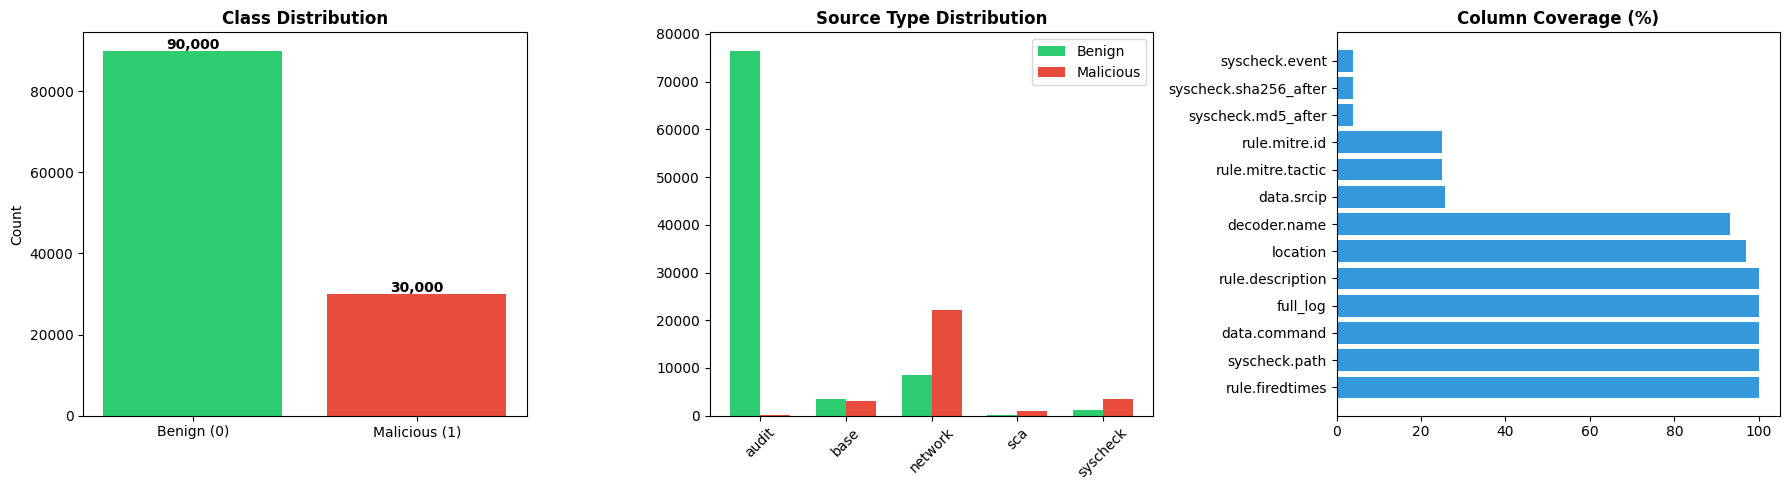


Dashboard saved to D:\PFE_BENIGN_MAL/dataset_summary.png

Sample benign rows:


,malicious,source_type,_source.decoder.name,_source.rule.firedtimes,_source.location,_source.data.srcip,_source.syscheck.path,_source.syscheck.md5_after,_source.syscheck.sha256_after,_source.syscheck.event,_source.data.command,_source.full_log,_source.rule.description,_source.rule.mitre.tactic,_source.rule.mitre.id
0,0,network,web-accesslog,2349,/var/log/apache2/access.log,192.168.217.1,/usr/bin/perlbug,NaN,NaN,NaN,,192.168.204.1 - - [20/Oct/2023:23:20:11 +0500]...,Web server 400 error code.,NaN,NaN
1,0,audit,auditd,1794,/var/log/audit/audit.log,NaN,/usr/bin/libnetcfg,NaN,NaN,NaN,,type=SYSCALL msg=audit(1704027619.776:14534): ...,Audit: Command: /usr/bin/dash.,NaN,NaN
2,0,audit,auditd,140,/var/log/audit/audit.log,NaN,/usr/bin/pdfunite,NaN,NaN,NaN,,type=SYSCALL msg=audit(1704301330.331:659): ar...,Audit: Command: /snap/snapd/20290/usr/lib/snap...,NaN,NaN
3,0,audit,auditd,6699,/var/log/audit/audit.log,NaN,/usr/bin/pdfattach,NaN,NaN,NaN,,type=SYSCALL msg=audit(1704027585.892:12993): ...,Audit: Command: /usr/bin/mkdir.,NaN,NaN
4,0,audit,auditd,3954,/var/log/audit/audit.log,NaN,/usr/bin/encguess,NaN,NaN,NaN,,type=SYSCALL msg=audit(1704027585.892:12993): ...,Audit: Command: /usr/bin/mkdir.,NaN,NaN



Sample malicious rows:


,malicious,source_type,_source.decoder.name,_source.rule.firedtimes,_source.location,_source.data.srcip,_source.syscheck.path,_source.syscheck.md5_after,_source.syscheck.sha256_after,_source.syscheck.event,_source.data.command,_source.full_log,_source.rule.description,_source.rule.mitre.tactic,_source.rule.mitre.id
90000,1,network,web-accesslog,829,/var/log/apache2/access.log,192.168.204.1,/usr/bin/pf2afm,NaN,NaN,NaN,,File '/etc/cups/subscriptions.conf' modified\n...,Integrity checksum changed.,"[""TA0001""]","[""T1190""]"
90001,1,network,web-accesslog,7322,/var/log/apache2/access.log,192.168.204.1,/usr/bin/json_pp,NaN,NaN,NaN,,type=SYSCALL msg=audit(1704304031.236:3170): a...,Audit: Command: /usr/bin/gawk.,"[""TA0005"",""TA0004"",""TA0007"",""TA0001""]","[""T1055"",""T1083"",""T1190""]"
90002,1,syscheck,syscheck_deleted,264,syscheck,NaN,/tmp/go-build2314020258/b054/_pkg_.a,fcf6736934ddb5b9cb29cdf8145c29fb,d6665d455cf0909522a81a73c14bfddc9b81e1612e531c...,deleted,,192.168.204.1 - - [06/Oct/2023:01:21:06 +0500]...,Common web attack.,"[""TA0005"",""TA0040""]","[""T1070.004"",""T1485""]"
90003,1,syscheck,syscheck_deleted,299,syscheck,NaN,/tmp/go-build2724593589/b025/importcfg,2f987a7ecd783c805a56aa3f4af7f9c4,665008523f0fda21401bf24bbd8d881a6a252b1c4c2750...,deleted,,192.168.204.1 - - [06/Oct/2023:01:21:06 +0500]...,Common web attack.,"[""TA0005"",""TA0040""]","[""T1070.004"",""T1485""]"
90004,1,network,web-accesslog,710,/var/log/apache2/access.log,192.168.217.1,/usr/bin/free,NaN,NaN,NaN,,type=SYSCALL msg=audit(1704304031.236:3170): a...,Audit: Command: /usr/bin/gawk.,"[""TA0005"",""TA0004"",""TA0007"",""TA0001""]","[""T1055"",""T1083"",""T1190""]"


In [24]:
# ============================================================================
# DATASET SUMMARY & VISUALIZATION
# ============================================================================

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Class distribution
class_counts = reverse_df['malicious'].value_counts().sort_index()
bars = axes[0].bar(['Benign (0)', 'Malicious (1)'],
                   [class_counts.get(0, 0), class_counts.get(1, 0)],
                   color=['#2ecc71', '#e74c3c'])
for bar in bars:
    axes[0].text(bar.get_x() + bar.get_width()/2., bar.get_height() + 500,
                 f'{int(bar.get_height()):,}', ha='center', fontweight='bold')
axes[0].set_title('Class Distribution', fontweight='bold')
axes[0].set_ylabel('Count')

# 2. Source type distribution
src_benign = reverse_df[reverse_df['malicious']==0]['source_type'].value_counts()
src_mal = reverse_df[reverse_df['malicious']==1]['source_type'].value_counts()
all_types = sorted(set(src_benign.index) | set(src_mal.index))
x = np.arange(len(all_types))
w = 0.35
axes[1].bar(x - w/2, [src_benign.get(t, 0) for t in all_types], w, label='Benign', color='#2ecc71')
axes[1].bar(x + w/2, [src_mal.get(t, 0) for t in all_types], w, label='Malicious', color='#e74c3c')
axes[1].set_xticks(x)
axes[1].set_xticklabels(all_types, rotation=45)
axes[1].legend()
axes[1].set_title('Source Type Distribution', fontweight='bold')

# 3. Non-null coverage
cols_to_check = [c for c in reverse_df.columns if c.startswith('_source.')]
coverage = [(c.replace('_source.',''), reverse_df[c].notna().mean()*100) for c in cols_to_check]
coverage.sort(key=lambda x: x[1], reverse=True)
axes[2].barh([c[0] for c in coverage], [c[1] for c in coverage], color='#3498db')
axes[2].set_xlim(0, 105)
axes[2].set_title('Column Coverage (%)', fontweight='bold')

plt.tight_layout()
save_dir = Path(OUTPUT_DIR)
plt.savefig(save_dir / 'dataset_summary.png', dpi=150, bbox_inches='tight')
plt.show()
print(f"\nDashboard saved to {OUTPUT_DIR}/dataset_summary.png")

# Show sample
print(f"\nSample benign rows:")
display(reverse_df[reverse_df['malicious']==0].head(5))
print(f"\nSample malicious rows:")
display(reverse_df[reverse_df['malicious']==1].head(5))